In [1]:
import pandas as pd

df = pd.read_csv("iris.csv")

print("Dataset shape:", df.shape)
display(df.head())
print(df["species"].value_counts())

Dataset shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("iris.csv")

print("Dataset shape:", df.shape)
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

print("\nSpecies counts:")
print(df["species"].value_counts())

Dataset shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Missing values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Species counts:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


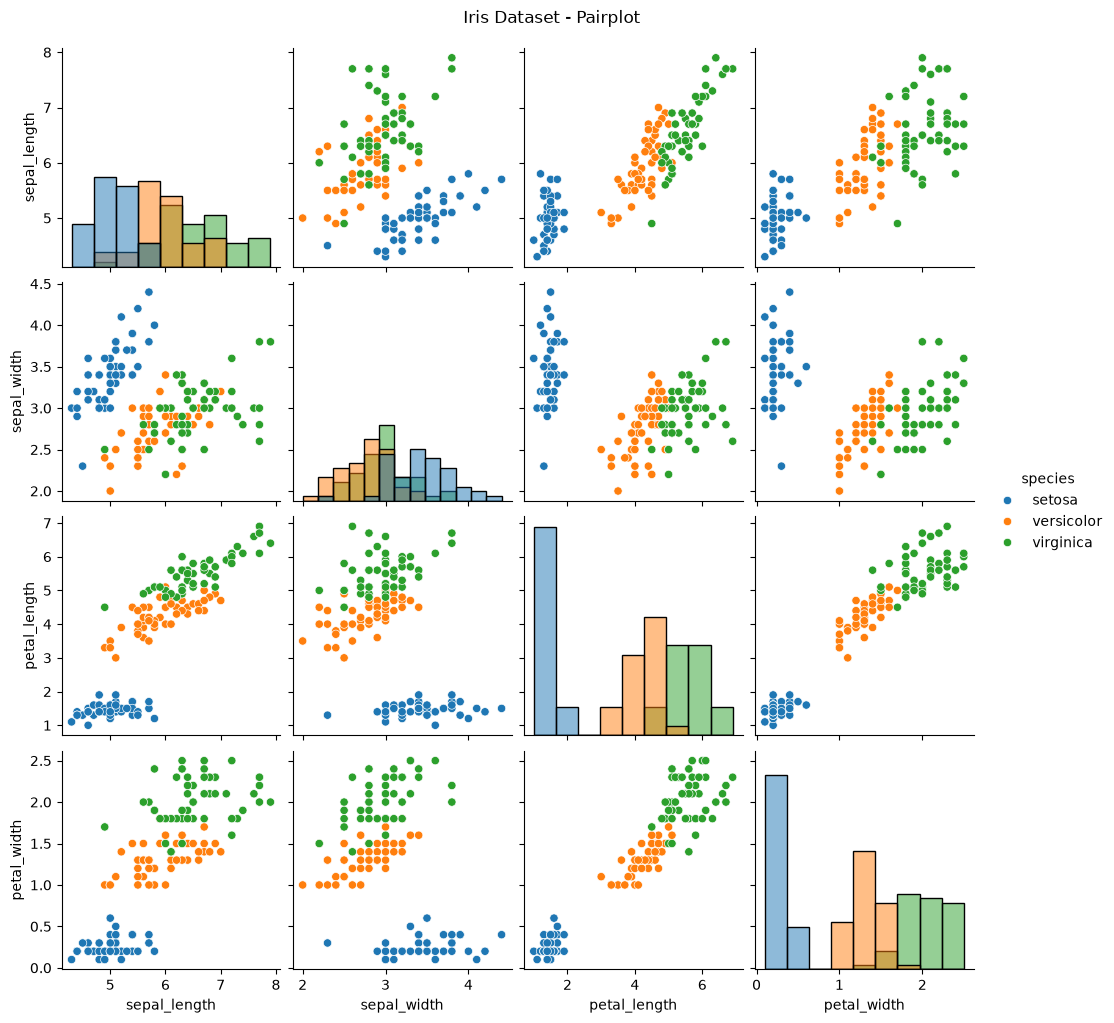

In [4]:
sns.pairplot(df, hue="species", diag_kind="hist")
plt.suptitle("Iris Dataset - Pairplot", y=1.02)
plt.show()

In [5]:
features = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width"
]

X = df[features]
y = df["species"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (150, 4)
Target shape: (150,)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 120
Testing samples: 30


In [7]:
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    ),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    print(name, "trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!


In [8]:
for name, pred in predictions.items():
    print("\n", name)
    print(classification_report(y_test, pred, zero_division=0))


 Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


 Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [9]:
results = []

for name, pred in predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, average="macro", zero_division=0
        ),
        "F1-score": f1_score(
            y_test, pred, average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4))

,Accuracy,Precision,Recall,F1-score
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9333,0.9333,0.9333,0.9333


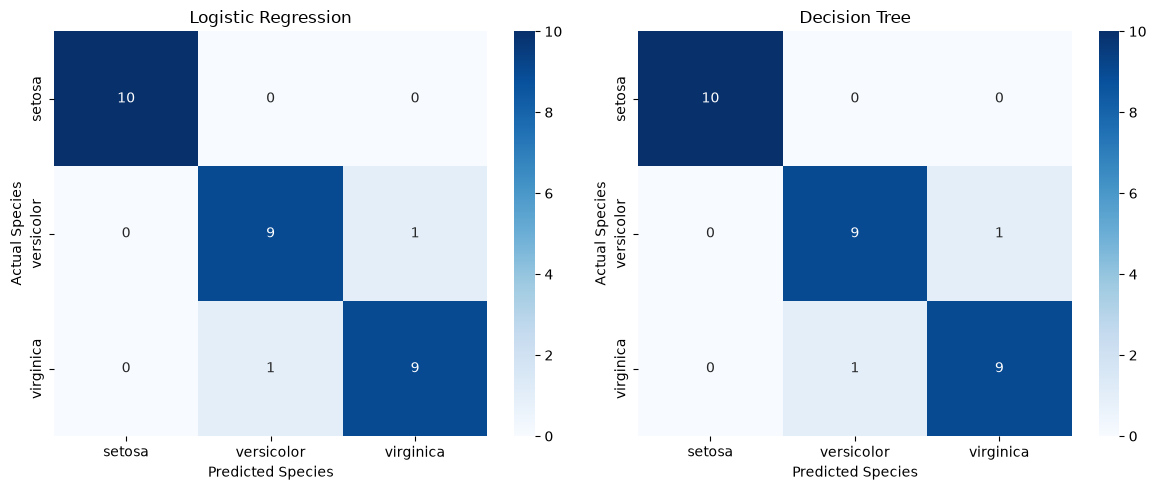

In [10]:
species_order = ["setosa", "versicolor", "virginica"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(
        y_test, pred, labels=species_order
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=species_order,
        yticklabels=species_order,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Species")
    ax.set_ylabel("Actual Species")

plt.tight_layout()
plt.show()

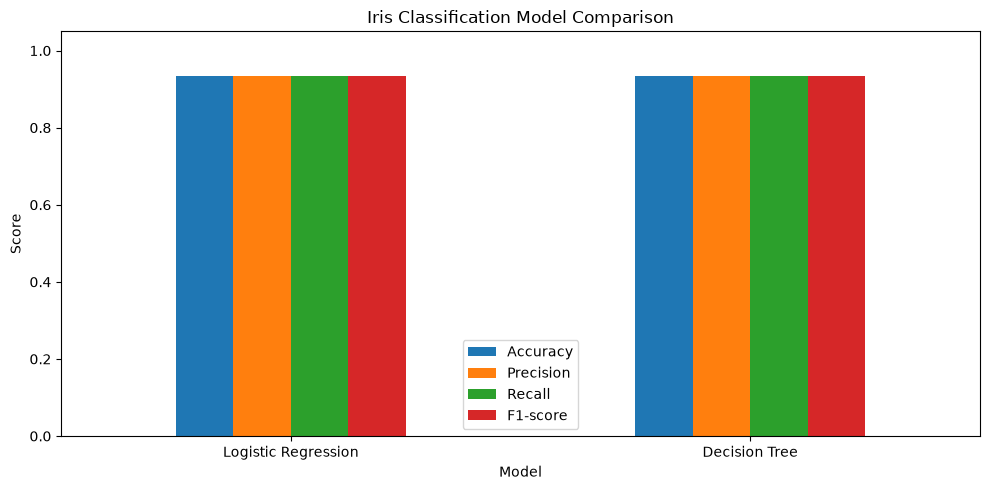

In [11]:
results_df.plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1.05)
)

plt.title("Iris Classification Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

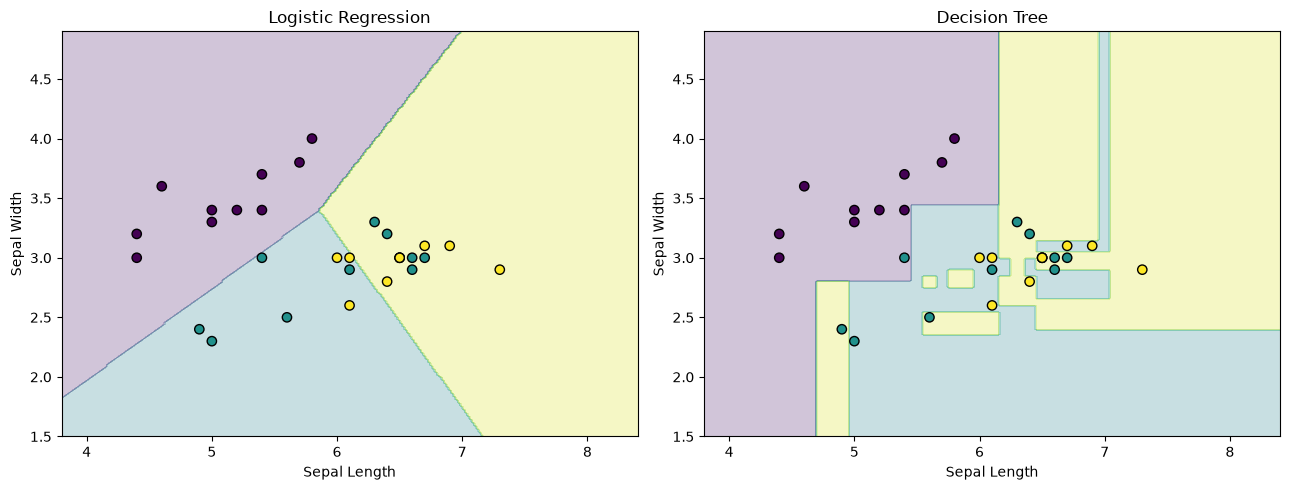

In [12]:

# Use two features so we can visualize the decision boundaries
boundary_features = ["sepal_length", "sepal_width"]
X_2d = df[boundary_features]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_2d,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

boundary_models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    ),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

species_order = sorted(y.unique())
class_to_num = {
    label: i for i, label in enumerate(species_order)
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

x_min = X_2d["sepal_length"].min() - 0.5
x_max = X_2d["sepal_length"].max() + 0.5
y_min = X_2d["sepal_width"].min() - 0.5
y_max = X_2d["sepal_width"].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

grid = pd.DataFrame({
    "sepal_length": xx.ravel(),
    "sepal_width": yy.ravel()
})

for ax, (name, model) in zip(axes, boundary_models.items()):
    model.fit(X2_train, y2_train)

    predicted = model.predict(grid)
    Z = pd.Series(predicted).map(class_to_num).to_numpy()
    Z = Z.reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.25, cmap="viridis")

    ax.scatter(
        X2_test["sepal_length"],
        X2_test["sepal_width"],
        c=y2_test.map(class_to_num),
        cmap="viridis",
        edgecolors="black",
        s=45
    )

    ax.set_title(name)
    ax.set_xlabel("Sepal Length")
    ax.set_ylabel("Sepal Width")

plt.tight_layout()
plt.show()
